<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[4, 3, 7, 5, 7]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0260
3     0.0535
4     0.0833
5     0.1129
6     0.1400
7     0.1665
8     0.1427
9     0.1126
10    0.0831
11    0.0525
12    0.0269
Name: count, dtype: float64


<Axes: >

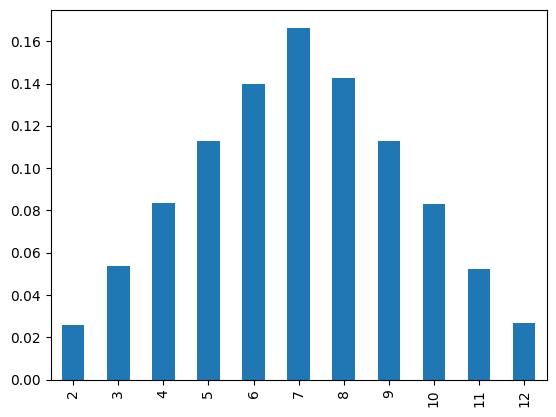

In [7]:
s.plot(kind='bar')

<Axes: >

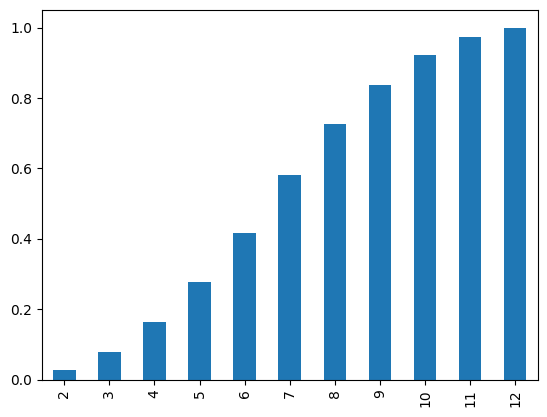

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[54.00223447 41.60896866 56.23801936 40.67026093 51.16121478 61.309128
 45.10813833 54.89650098 51.32939743 55.39752515 50.36702086 47.57253881
 56.30192978 40.66875358 45.94018289 47.85922508 48.89744668 52.81828811
 52.50970788 40.8798266  53.43518428 50.70055318 44.99695904 47.0501297
 45.25657485 40.4825823  47.88659071 45.54142726 56.16385161 47.01396353
 47.50962421 48.33055866 42.02891075 49.18529265 49.30872774 49.97172324
 52.41995721 52.70859489 51.11336755 43.91996484 50.13308325 51.05022059
 46.35146719 51.00707603 53.13408169 59.96861038 45.31256901 46.15933428
 42.18190059 49.62542734 48.47584205 49.05551079 40.30059482 45.68142384
 47.67174229 42.24685418 48.29478841 55.46511132 47.36020339 42.85391644
 50.09462868 53.1679519  44.98164698 50.12365922 57.90016611 48.83278483
 59.73426636 47.6505384  55.46733708 49.49345806 43.37925875 49.10621277
 53.52830836 58.94439409 41.53510327 49.07604298 52.87195889 40.63061171
 54.19961829 41.27415608 52.09795873 48.61294462 43.90

In [10]:
sample.mean()

np.float64(49.82070636258966)

(array([  3.,   4.,  44., 107., 189., 282., 196., 123.,  40.,  12.]),
 array([31.46567579, 34.77343832, 38.08120084, 41.38896337, 44.69672589,
        48.00448842, 51.31225095, 54.62001347, 57.927776  , 61.23553852,
        64.54330105]),
 <BarContainer object of 10 artists>)

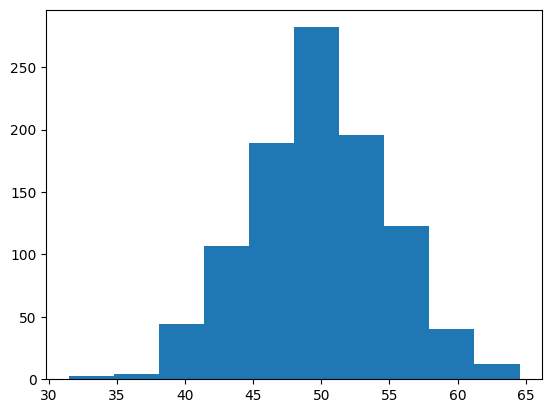

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(31.46567579035039)

In [15]:
sample.max()

np.float64(64.54330104927769)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

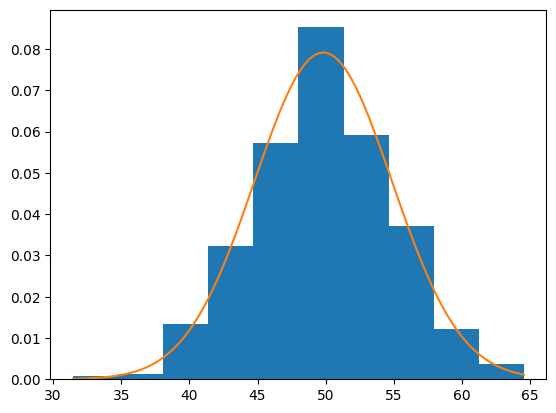

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_700/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

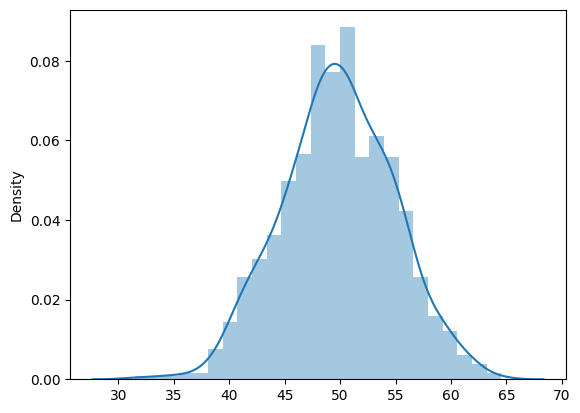

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([16.05148284, 21.60857435, 19.14718515, 15.10645249, 19.71481236,
       23.98416966, 20.637936  , 22.65757053, 24.35104173, 14.18177154,
       19.96920536, 22.68692127,  9.82185104, 21.18899033, 16.52637444,
       20.85931398, 24.38592401, 21.56902369, 12.08579677, 31.1147567 ,
       19.57120861, 21.38590275, 21.85052315, 17.93718429, 20.82399541,
       11.21300919, 15.91847286, 15.90964623, 14.23009763, 15.85734427,
       20.6632772 , 20.15298856, 24.53508195, 19.70447325, 27.03255937,
       24.09699511, 22.9277822 , 20.03706126, 25.27694117, 21.35087942,
       17.86370564, 20.17405316, 25.55565112, 15.4170598 , 15.84597849,
       26.78669163, 17.60265126, 25.37570666, 26.2418978 , 22.54056293,
       19.65303318, 14.61751329, 18.50691618, 28.5752869 , 13.27647884,
       23.1825775 , 22.4245705 , 17.43646998, 19.55647155, 22.71356682,
       18.99618905, 19.12385491, 21.41291429,  7.07445773, 25.34155098,
       21.12818713, 26.11298513,  8.91539917, 24.11664317, 16.90

(array([ 2.,  0.,  0.,  0.,  3.,  3.,  2.,  2.,  4., 10.,  8., 11., 13.,
        25., 16., 21., 33., 38., 23., 20., 18., 13., 13.,  9.,  6.,  8.,
         9., 18., 11., 32., 29., 56., 53., 58., 46., 58., 64., 69., 45.,
        37., 35., 18., 18., 14., 14.,  5.,  6.,  3.,  0.,  1.]),
 array([ 1.67027501,  2.75311035,  3.83594568,  4.91878102,  6.00161636,
         7.0844517 ,  8.16728704,  9.25012238, 10.33295772, 11.41579306,
        12.4986284 , 13.58146374, 14.66429907, 15.74713441, 16.82996975,
        17.91280509, 18.99564043, 20.07847577, 21.16131111, 22.24414645,
        23.32698179, 24.40981713, 25.49265247, 26.5754878 , 27.65832314,
        28.74115848, 29.82399382, 30.90682916, 31.9896645 , 33.07249984,
        34.15533518, 35.23817052, 36.32100586, 37.4038412 , 38.48667653,
        39.56951187, 40.65234721, 41.73518255, 42.81801789, 43.90085323,
        44.98368857, 46.06652391, 47.14935925, 48.23219459, 49.31502993,
        50.39786526, 51.4807006 , 52.56353594, 53.64637128,

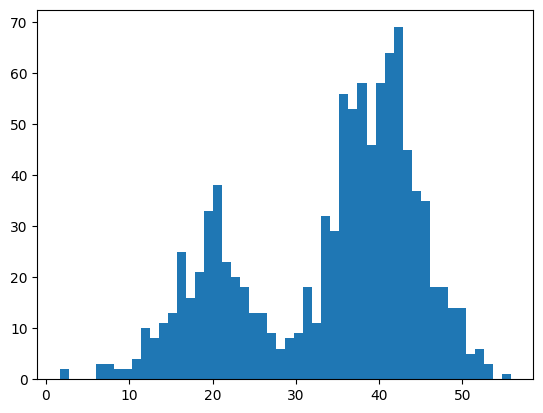

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

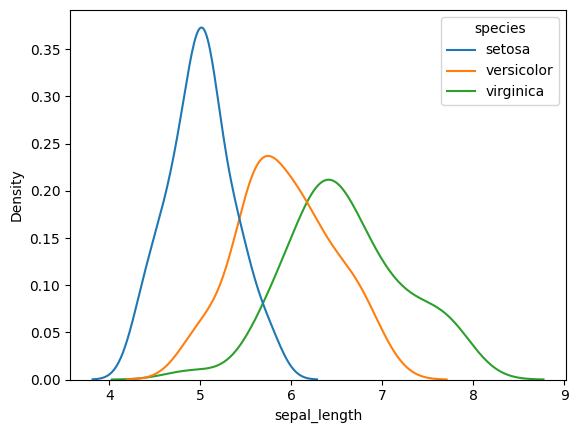

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

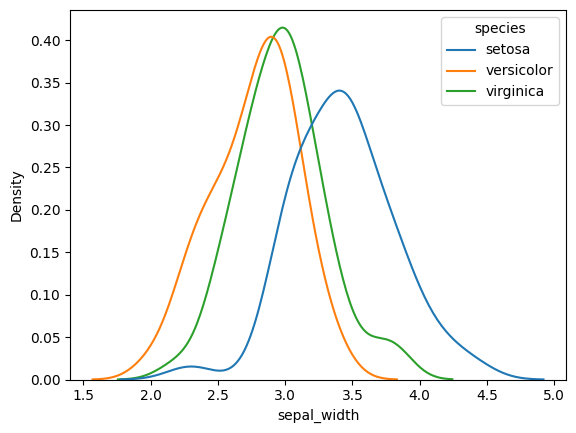

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

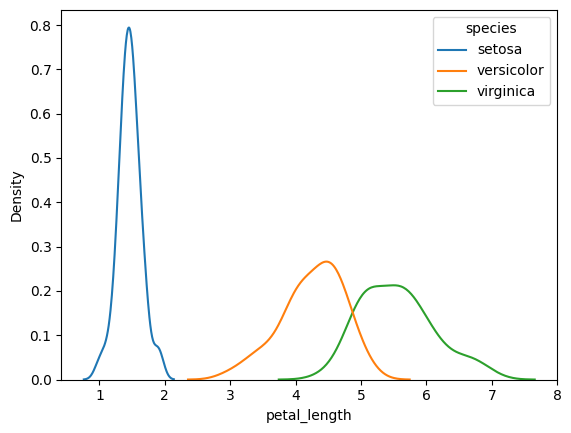

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

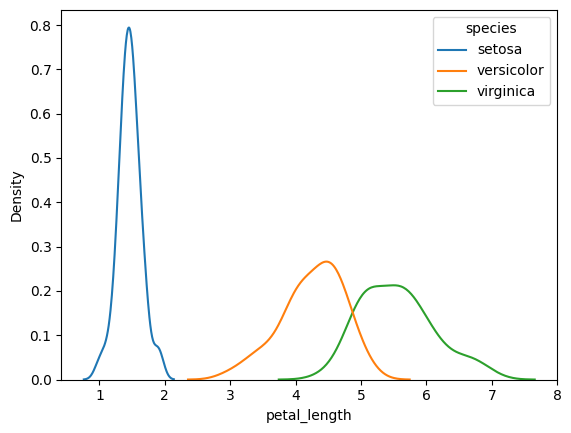

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

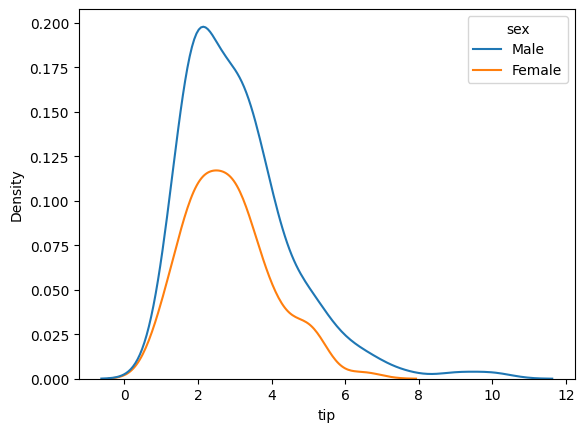

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

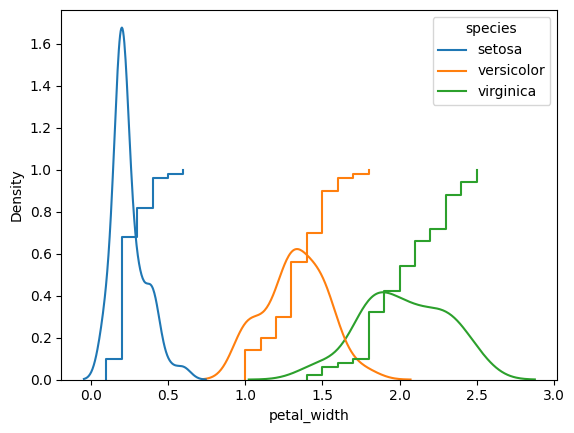

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

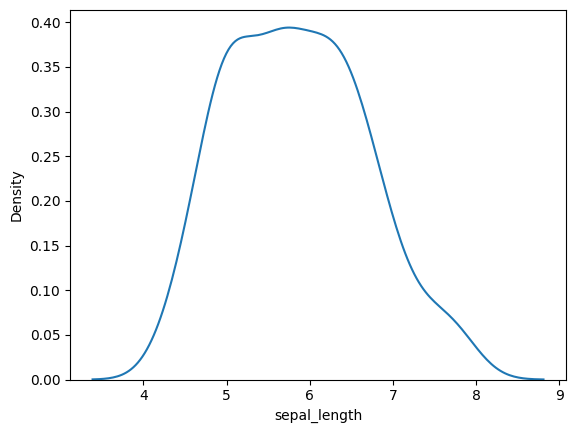

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

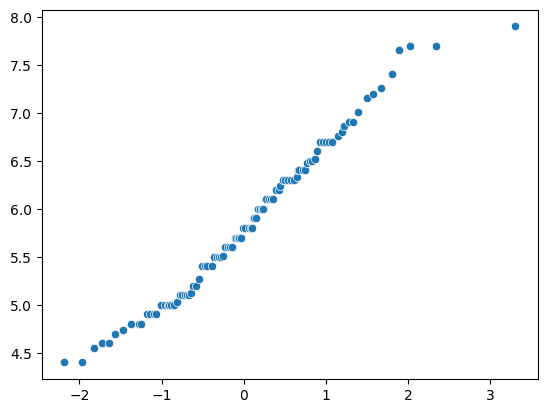

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

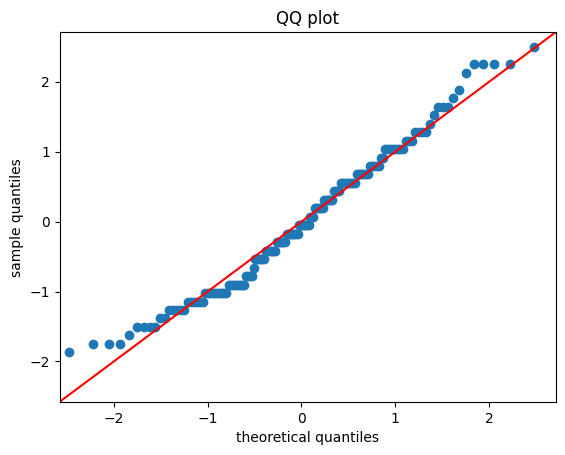

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [43]:
import scipy.stats as stats

In [44]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([102.,  83., 107., 113., 114.,  91., 118.,  93.,  83.,  96.]),
 array([6.48279265e-04, 1.00544251e-01, 2.00440223e-01, 3.00336195e-01,
        4.00232167e-01, 5.00128139e-01, 6.00024111e-01, 6.99920083e-01,
        7.99816055e-01, 8.99712027e-01, 9.99607999e-01]),
 <BarContainer object of 10 artists>)

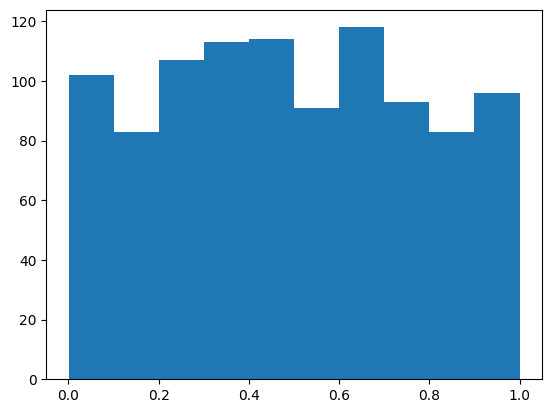

In [45]:
plt.hist(x)

PARETO DISTRIBUTION

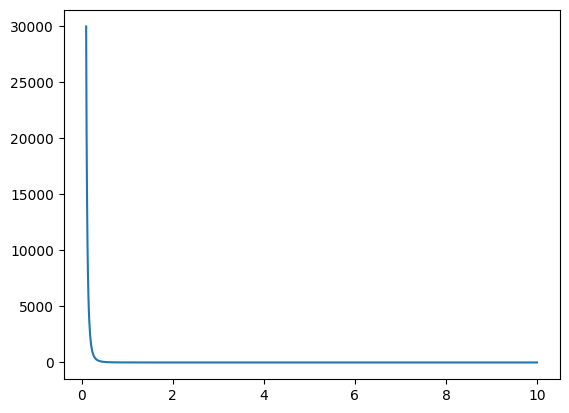

In [46]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

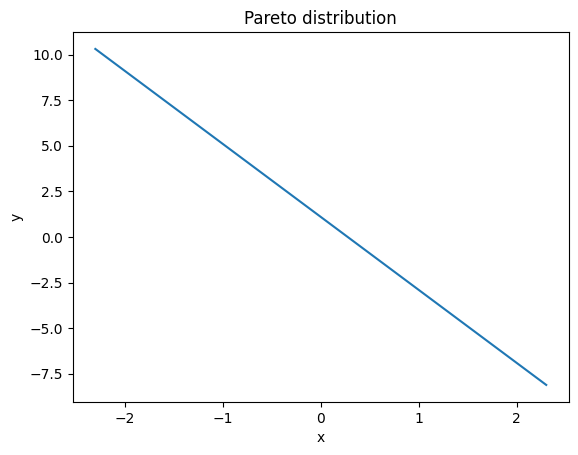

In [47]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [48]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([948.,  33.,  12.,   3.,   1.,   0.,   2.,   0.,   0.,   1.]),
 array([ 1.00026123,  4.69369051,  8.3871198 , 12.08054908, 15.77397836,
        19.46740764, 23.16083692, 26.8542662 , 30.54769549, 34.24112477,
        37.93455405]),
 <BarContainer object of 10 artists>)

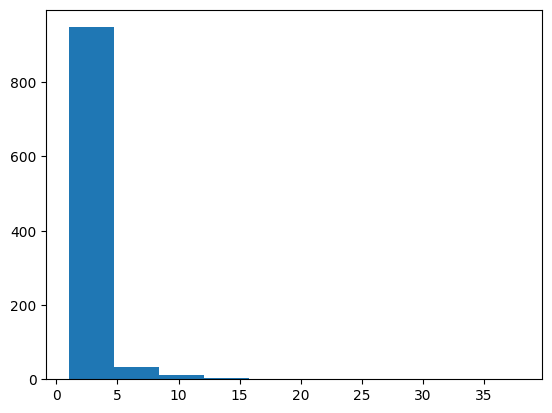

In [49]:
plt.hist(x)

In [50]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

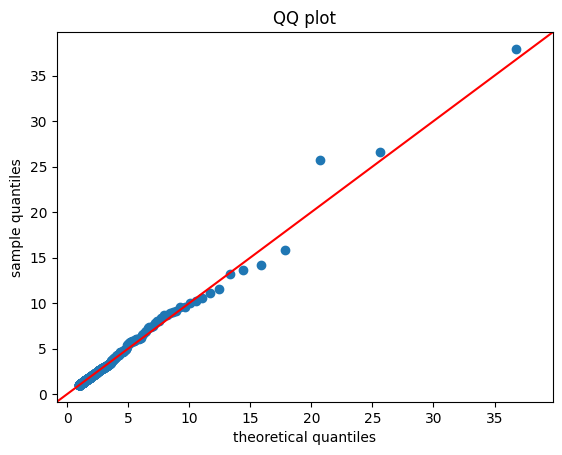

In [51]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [52]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [53]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [54]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [56]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_700/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

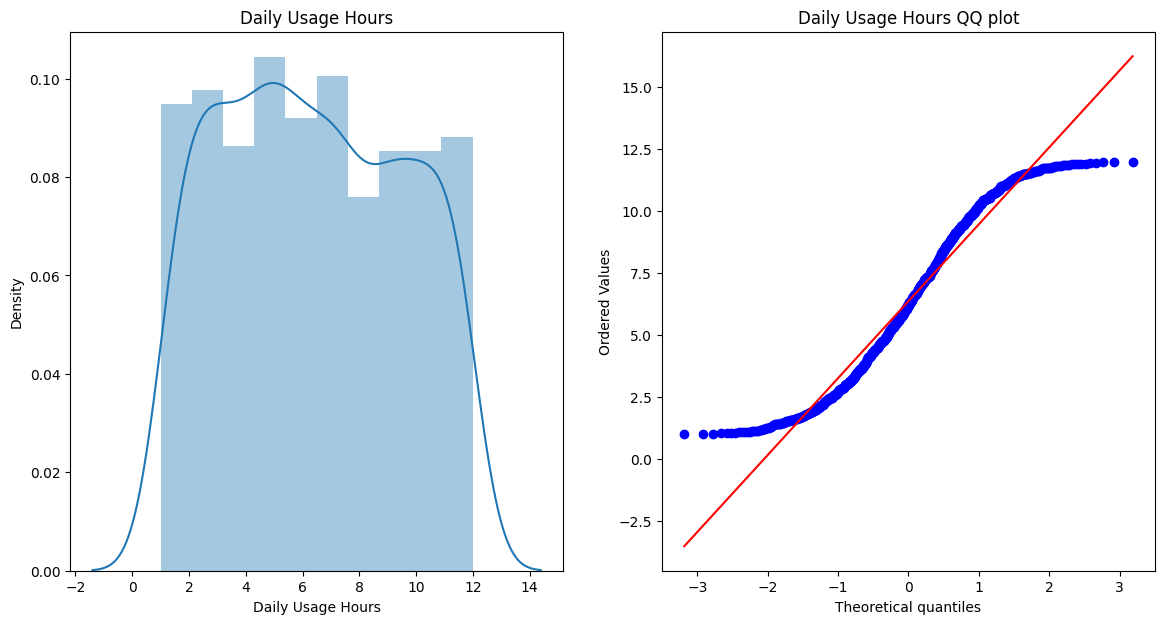

In [58]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

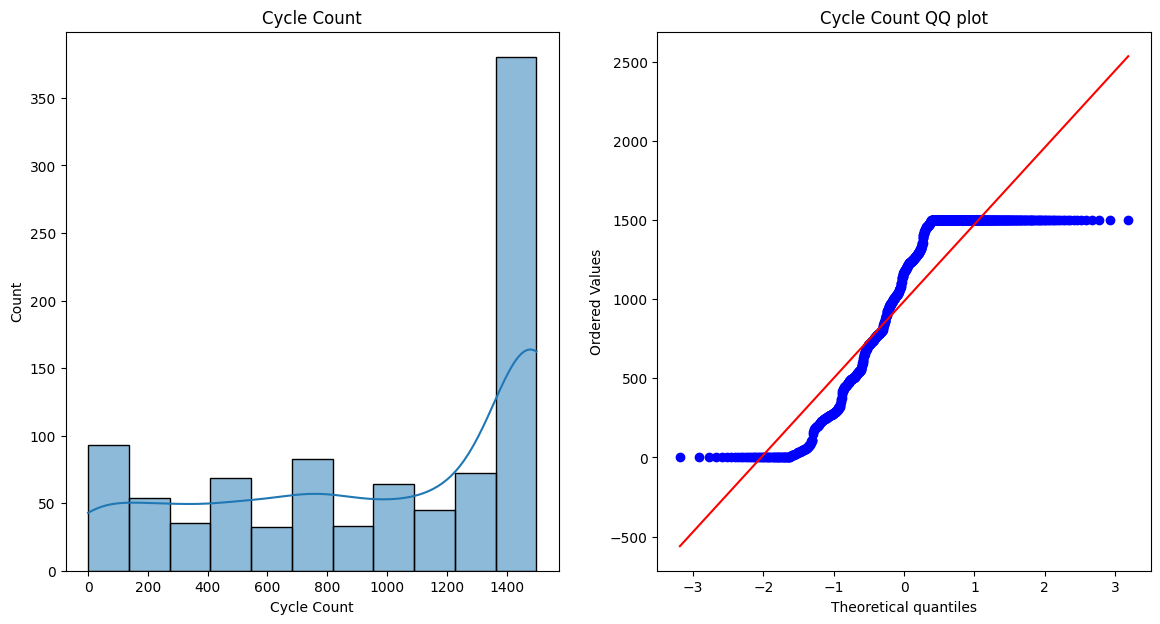

In [59]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [60]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [62]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [63]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [64]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.45416666666666666
Accuracy DT 0.7333333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
trf=FunctionTransformer(np.log1p)

In [66]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
597            1.791061          0.0        11.284782     7.237059
482            1.688876          0.0        10.911372     7.313887
766            2.152775          0.0        10.866681     7.142827
411            2.356932          0.0        10.783944     6.159095
321            2.418357          0.0        10.837874     6.655440
...                 ...          ...              ...          ...
168            2.086398          0.0        10.938361     7.313887
861            1.913954          0.0        11.053395     6.284134
573            1.745202          0.0        10.814283     7.128496
1045           2.111578          0.0        11.281523     6.232448
1192           2.055415          0.0        10.948752     7.313887

[960 rows x 4 columns]
      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
271            2.453620     0.000000        11.188980     5.828946
263            1.815385     0.000000  

In [67]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.4875
Accuracy DT 0.7166666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 5  6  8  6  2  6  4  3  5  4  8  7  5  7  5  6  6  5  6  4  5  5  6  5
  5  5  5  6  3  5  7  7  5  5  6  6  4  5  3  4  5  5  4  5  5  4  7  4
  6  6  6  7  5  4  7  3  5  2  5  7  4  8  7  3  2  5  6  4  8  5  4  6
  3  6  3  5  3  6  3  7  4  7  4  4  4  7  7  5  8  7  5  2  1  6  4  6
  3  5  4  4  5  7  3  4  6  3  8  6  6  3  2  4  6  5  8  7  3  6  5  3
  2  7  4  4  5  3 10  5  5  3  6  4  3  4  4  5  8  5  1  8  6  6  4  7
  4  5  4  5  4  5  5  5  8  4  3  6  3  5  7  4  5  5  6  4  5  6  4  5
  8  6  1  2  6  6  9  3  6  7  3  6  4  2  5  3  6  4  5  5  4  7  3  7
  3  8  3  4  4  4  6  5  8  4  6  7  3  7  6  2  4  3  6  6  6  2  6  5
  6  5  1  1  5  6  2  5  6  3  5  6  3  7  6  5  2  6  5  6  3  3  6  4
  5  4  8  4  5  6  5  5  4  5  3  6  5  7  2  7  6  3  6  7  6  3  4  7
  5  4  5  7  6  7  5  6  6  6  2  3  6  5  7  8  4  7  5  4  6  6  5  3
  6  6  5  5  5  3  5  4  5  3  7  5  7  5  4  4  3  4  3  5  4  8  7  5
  7  6  4  7  3  6  2  2  5  3  5  6  2  7  5  3  6

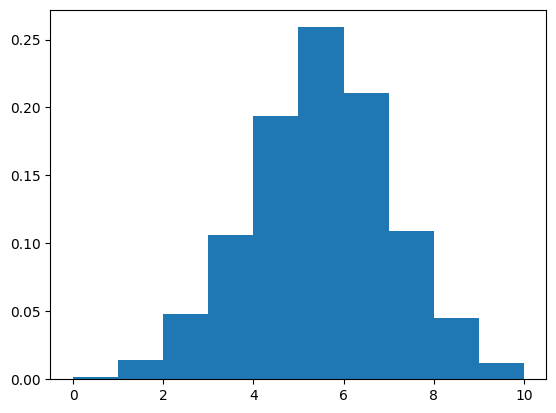

In [68]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [69]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [70]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.50087034, 0.50687603, 0.49314327, ..., 0.49365137, 0.49282036,
       0.5212881 ])

In [71]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

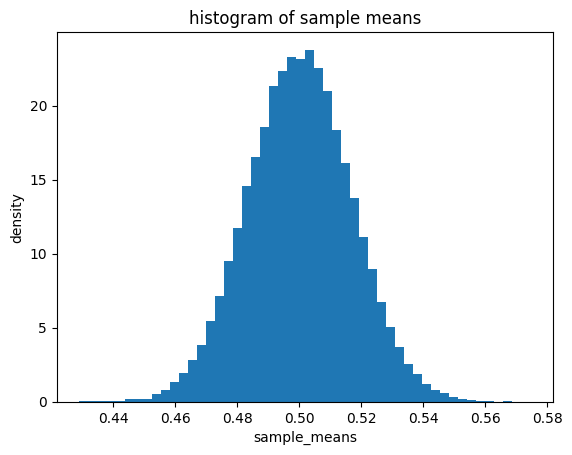

In [72]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [73]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

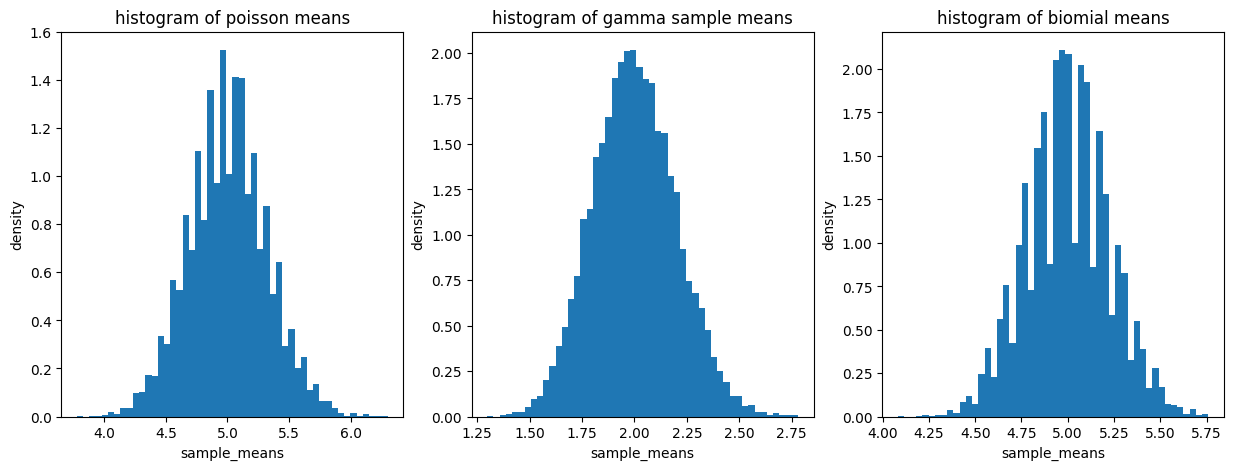

In [74]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [75]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 1.9929728128402673
Emperical variance: 0.06565604660788427


CASE STUDY

In [76]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [77]:
battery_csv.shape

(1200, 11)

In [78]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
1142,6,7.706501,0,54617,1500,57.123756,46.662253,79.690197,31.428688,39862.685348,73.289695
578,0,1.545665,0,75382,16,24.222871,18.813661,41.637724,32.827352,75382.000000,100.000000
438,6,5.591343,0,69544,1467,41.021084,21.377574,60.651384,29.129455,54625.315569,75.117371
653,9,7.570436,0,57002,1500,42.767491,29.652429,59.932944,32.055982,41020.150959,72.406472
424,4,1.076805,0,58895,958,21.785230,12.105607,41.091838,32.815734,48773.718019,82.890215
...,...,...,...,...,...,...,...,...,...,...,...
698,2,7.857175,0,79790,497,54.523249,35.702751,68.653203,30.229785,74226.880507,91.007920
379,8,1.002497,0,74256,1500,16.378392,9.582086,40.746049,29.733764,57465.395999,78.641479
1014,5,7.635700,0,71707,1182,55.504809,36.189562,78.177252,31.831699,60073.949364,87.114782
169,0,5.481021,0,71425,103,45.987869,32.303868,73.594234,30.402286,70553.058802,98.445600


In [79]:
d['Daily Usage Hours'].mean()

np.float64(6.435078131250979)

<Axes: ylabel='Density'>

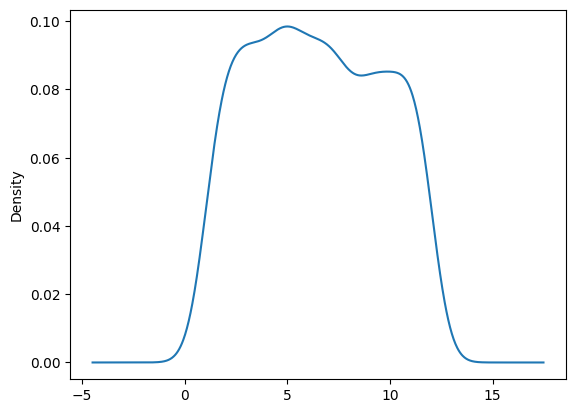

In [80]:
d['Daily Usage Hours'].plot(kind='density')

In [81]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
1139,11.861053
411,9.558509
495,11.489959
1063,6.787034
899,7.402771
918,11.690298
1064,8.565461
1033,3.621186
1068,1.542239
210,8.293299


In [82]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[6.302190737546257,
 1.4436723735229715,
 4.6788677982991445,
 8.11048112750898,
 7.262354828534222,
 3.391982254389595,
 4.785007796343863,
 6.308613592276728,
 4.8285715102505256,
 3.2439406397032613,
 3.3206687968194544,
 6.89096720407578,
 8.02859324170613,
 5.628102188254784,
 8.131272800286816,
 3.31117912203587,
 9.432555391832569,
 11.350915548318808,
 4.434087102260424,
 9.826356336089958,
 1.071107935686816,
 6.704178575323073,
 1.2634089179753183,
 3.2657803946465784,
 6.725982210353442,
 5.981072858127595,
 2.531794778631744,
 8.431454509241828,
 1.9394333317899384,
 10.295436137863067,
 2.796898947174721,
 1.6046293752380427,
 8.445595034103341,
 9.383920458998093,
 4.727058306650881,
 4.498435728639719,
 1.0680220490498633,
 9.360060994583083,
 2.297697319908677,
 8.875831628958966,
 6.0437041840571695,
 10.263819143154192,
 1.70504182139793,
 2.199149772050216,
 7.350887413416345,
 2.987232954424335,
 7.102049836105897,
 2.071035831703432,
 5.420638983604134,
 1.96567060

In [83]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [84]:
samples

[[7.0026556569432845,
  3.1613566365183225,
  1.437925833903292,
  4.01386909416969,
  1.4319155681352624,
  11.043456135788416,
  3.329204482576615,
  8.803277040068249,
  4.816548454153445,
  1.897324181725025,
  4.1104200276610845,
  4.903150410974789,
  5.3757278502200805,
  3.7497017995571262,
  11.424547947707076,
  6.815222643882032,
  5.123074167849975,
  9.157900161970778,
  4.67611985590421,
  9.1660693079876,
  5.981072858127595,
  7.34199488946254,
  2.86875780540963,
  3.3206687968194544,
  6.549015358362909,
  4.837150982044932,
  4.4421150283170485,
  4.233084365554271,
  4.606271216744001,
  6.386084836352359,
  2.3474764816258813,
  5.249164756600997,
  7.139883022794848,
  4.71063669730342,
  4.159433301256659,
  8.875831628958966,
  3.5614441256370366,
  6.335197862764454,
  1.7017401187895764,
  4.471965369038675,
  7.549030071725599,
  7.15139944945304,
  1.581093550011942,
  11.24914443648159,
  11.442004168701786,
  2.31054739195653,
  4.386010650287311,
  3.7339

In [85]:
samples=np.array(samples)
samples

array([[ 7.00265566,  3.16135664,  1.43792583, ...,  3.73393803,
        10.29350494,  8.33174174],
       [ 5.51867691,  7.72475822,  6.62958502, ...,  7.21957534,
         5.52224759,  9.02240781],
       [ 6.98683071,  6.5651838 ,  1.14551694, ...,  6.73514724,
         2.82880863,  2.71998356],
       ...,
       [11.00923174, 10.53766201,  5.50100846, ...,  6.14492678,
         2.31319112,  7.83463687],
       [11.81013495,  1.58018347,  1.93462919, ...,  6.24681732,
        11.81674845,  2.34747648],
       [ 2.82880863,  1.75005282,  3.88649214, ...,  1.40107156,
        11.89313688,  7.05584849]])

In [86]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [87]:
sampling_means.mean()

np.float64(6.513934048844678)

In [88]:
sampling_means.std()/np.sqrt(50)

np.float64(0.06694451008015471)

<Axes: ylabel='Density'>

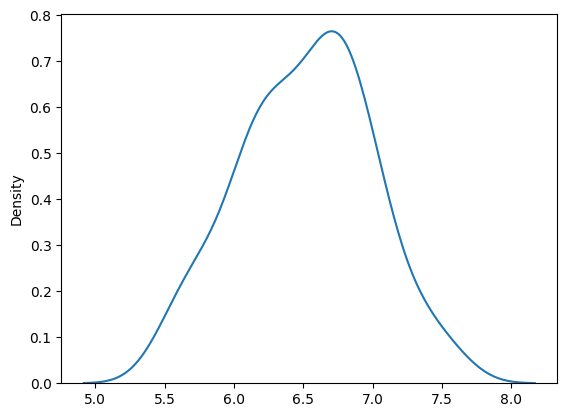

In [89]:
sns.kdeplot(data=sampling_means)

In [90]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.380045028684369 - 6.647823069004988


t-test

In [91]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [92]:
train=df.drop(columns=['Battery Health'])
test=df['Battery Health']

In [93]:
final=pd.concat([train,test]).sample(1000)

In [94]:
corr = df.corr(numeric_only=True)['Battery Health'].drop(
    'Battery Health'
)
print(corr)

Battery Age            -0.900723
Daily Usage Hours      -0.084347
Gaming User             0.018509
Design Capacity         0.289450
Cycle Count            -0.921454
CPU Usage              -0.052363
GPU Usage              -0.033122
Power Consumption      -0.048988
Average Temperature    -0.041134
Full Charge Capacity    0.704030
Name: Battery Health, dtype: float64


In [95]:
meanf=np.mean(df['Full Charge Capacity'])
print(meanf)

51798.12594357623


In [96]:
#H_0:u=51798.13
#H_a:u!=51798.13

In [97]:
vals=final['Full Charge Capacity'].dropna()

In [98]:
sample_vals=vals.sample(200).values
sample_vals

array([54304.58227662, 38388.03105655, 41747.67721121, 48531.25050931,
       65975.53921835, 50808.89130536, 61273.9623725 , 53549.07586033,
       59135.57175313, 59985.13240222, 49643.93880531, 53509.24002703,
       70709.09189572, 70840.65906578, 44549.33859663, 43097.59537559,
       44978.69538076, 34490.91502898, 68001.47677036, 68922.17467724,
       59373.71304557, 75033.16500401, 41473.87165186, 39389.13492171,
       69570.2754917 , 43563.95738021, 50812.16900833, 42317.88780505,
       65580.40877522, 35758.41187172, 35760.68032546, 64410.20122498,
       38004.35761214, 48499.49083174, 39527.10272491, 35894.29548089,
       62139.74603952, 46401.24692271, 30993.31582413, 37147.49450584,
       64853.08603473, 46751.59922323, 40762.36602419, 47503.86958053,
       71164.26586773, 33427.87418275, 51932.79541331, 52268.47853621,
       52773.44034463, 60211.26966059, 46079.55035523, 41878.21504094,
       55724.36039107, 56217.52820421, 57782.89648361, 34470.95601174,
      

In [99]:
mean_s=np.mean(sample_vals)
print(mean_s)
std_s=np.std(sample_vals)
print(std_s)

52796.60757317638
12391.54596626823


In [100]:
#check normality using shapiro wilk test
from scipy.stats import shapiro

shapiro_s=shapiro(sample_vals)
print(shapiro_s)

ShapiroResult(statistic=np.float64(0.9766665114708285), pvalue=np.float64(0.0020529260470965606))


In [101]:
import scipy.stats as stats

t_statistics,p_value=stats.ttest_1samp(sample_vals,50000)
print(t_statistics,p_value/2)


3.183703210311711 0.0008438356966532424
